# 02 Epizode onesnaženja in zgodnje opozarjanje

**Namen:** razložiti, kdaj in zakaj se zrak v kotlini poslabša, in preveriti, ali bi preprosto pravilo iz vremenske napovedi dan prej opozorilo na epizodo. **Ciljna skupina:** odločevalci (občina, ARSO, civilna zaščita), posredno občani.

**Vhodi:** urne meritve ARSO PM10 in PM2.5 za Bežigrad, Celovško in Vič (**meritev**), urna inverzija iz meritev ARSO na Bežigradu in hribih (**izpeljano iz meritev**), reanaliza ERA5 za točko Bežigrad (**model**; veter, višina mejne plasti, temperatura, padavine), CAMS (**model**, regionalni, ~10 km) in CAMx ARSO (**model**, operativna napoved ARSO na mreži 4,4 km, `02_modeli/camx/`).

**Pošteno opozorilo:** ERA5 je *analiza* (najboljša rekonstrukcija vremena za nazaj), ne napoved. Pravilo, ki tu uporablja ERA5 za "jutri", je zgornja meja tega, kar bi dosegla resnična napoved; pri vremenski napovedi za jutri so napake večje in uspešnost nižja.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.insert(0, ".")
from paket import *
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100; pd.set_option("display.width", 160)

pm = nalozi_arso()                       # meritev, vse tri postaje
inv = nalozi_inverzijo()                 # izpeljano iz meritev
era = nalozi_era5("E403")                # model
cams = nalozi_cams("E403")               # model
camx = nalozi_camx("E403")               # model ARSO (CAMx, 4,4 km), ure napovedi +1 … +24 (isti dan)
camx_j = nalozi_camx_jutri("E403")       # isti model, ure +25 … +48 (napoved za jutri, izdana dan prej; 2023–2025)
print(f"ARSO: {len(pm):,} ur ({pm.time_utc.min():%Y-%m-%d} – {pm.time_utc.max():%Y-%m-%d}); ERA5: {len(era):,} ur; CAMS: {len(cams):,} ur; "
      f"CAMx: {len(camx):,} ur ({camx.time_utc.min():%Y-%m-%d} – {camx.time_utc.max():%Y-%m-%d})")

ARSO: 198,407 ur (2015-12-31 – 2026-11-20); ERA5: 95,256 ur; CAMS: 95,256 ur; CAMx: 34,014 ur (2023-01-01 – 2026-11-18)


## 1. Kaj je epizoda

Dnevna mejna vrednost PM10 po direktivi EU je **50 µg/m³** (dovoljenih 35 preseganj na leto). Dan štejemo kot *preseganje*, če je dnevno povprečje (UTC dan, vsaj 18 ur meritev) nad mejo. **Epizoda** = zaporedje dni s preseganjem na Bežigradu (najdaljši niz, mestno ozadje). Za vsak dan zabeležimo še, koliko od treh postaj je preseglo mejo.

In [2]:
dn = {k: dnevno(g.drop(columns="station_code")).set_index("dan") for k, g in pm.groupby("station_code")}
D = pd.DataFrame({"pm10": dn["E403"].pm10, "pm25": dn["E403"].pm25,
                  "pm10_celovska": dn["E405"].pm10, "pm10_vic": dn["E404"].pm10})
D["n_postaj_nad_mejo"] = (D[["pm10", "pm10_celovska", "pm10_vic"]] > MEJA_PM10_DAN_EU).sum(axis=1)
D["preseganje"] = D.pm10 > MEJA_PM10_DAN_EU
D["sezona"] = sezona(D.index.to_series())

# epizode: zaporedni dnevi s preseganjem na Bežigradu
blok = (D.preseganje != D.preseganje.shift()).cumsum()
ep = (D[D.preseganje].groupby(blok[D.preseganje])
        .agg(zacetek=("pm10", lambda s: s.index.min()), konec=("pm10", lambda s: s.index.max()), trajanje_dni=("pm10", "size"),
             vrh_pm10=("pm10", "max"), vrh_pm25=("pm25", "max"), povp_postaj_nad_mejo=("n_postaj_nad_mejo", "mean"))
        .reset_index(drop=True))
ep["sezona"] = sezona(ep.zacetek)
print(f"Dni s preseganjem PM10 na Bežigradu 2016–2026: {int(D.preseganje.sum())} od {D.pm10.notna().sum()} dni z meritvijo; epizod: {len(ep)}")
print("Najdaljše epizode:")
ep.sort_values("trajanje_dni", ascending=False).head(10).round(1)

Dni s preseganjem PM10 na Bežigradu 2016–2026: 195 od 3931 dni z meritvijo; epizod: 80
Najdaljše epizode:


,zacetek,konec,trajanje_dni,vrh_pm10,vrh_pm25,povp_postaj_nad_mejo,sezona
57,2022-01-13 00:00:00+00:00,2022-01-19 00:00:00+00:00,7,77.6,71.9,3.0,2021/22
6,2016-12-05 00:00:00+00:00,2016-12-10 00:00:00+00:00,6,94.5,NaN,1.0,2016/17
13,2017-01-20 00:00:00+00:00,2017-01-25 00:00:00+00:00,6,95.6,NaN,1.0,2016/17
14,2017-01-28 00:00:00+00:00,2017-02-02 00:00:00+00:00,6,112.0,NaN,1.0,2016/17
31,2018-12-26 00:00:00+00:00,2018-12-31 00:00:00+00:00,6,90.4,NaN,1.0,2018/19
40,2019-12-31 00:00:00+00:00,2020-01-04 00:00:00+00:00,5,94.3,NaN,1.0,2019/20
21,2017-12-20 00:00:00+00:00,2017-12-24 00:00:00+00:00,5,87.4,NaN,1.0,2017/18
9,2016-12-23 00:00:00+00:00,2016-12-27 00:00:00+00:00,5,102.5,NaN,1.0,2016/17
73,2024-12-28 00:00:00+00:00,2025-01-01 00:00:00+00:00,5,66.2,62.4,3.0,2024/25
70,2024-01-31 00:00:00+00:00,2024-02-04 00:00:00+00:00,5,75.1,60.0,3.0,2023/24


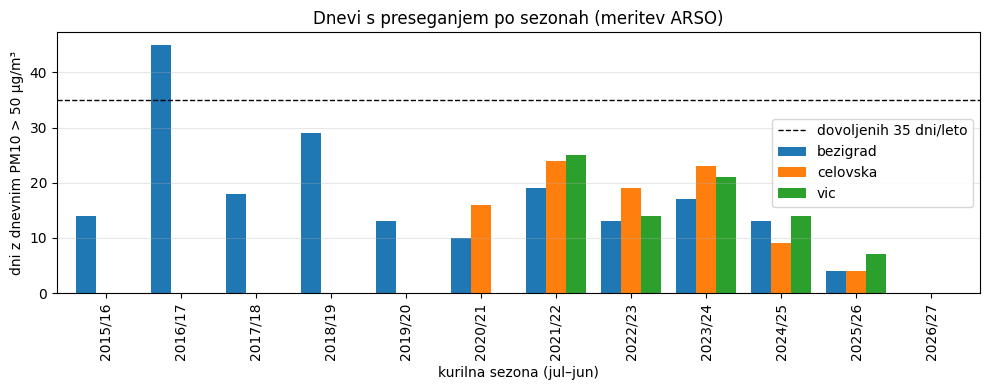

Opomba: Celovška meri od 2020, Vič od 2021; sezona 2026/27 je nepopolna.


In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
s = D.groupby("sezona").agg(bezigrad=("preseganje", "sum"), celovska=("pm10_celovska", lambda x: (x > 50).sum()), vic=("pm10_vic", lambda x: (x > 50).sum()))
s = s[s.index.str[:4].astype(int) >= 2015]
s.plot.bar(ax=ax, width=.8); ax.axhline(35, color="k", ls="--", lw=1, label="dovoljenih 35 dni/leto")
ax.set(ylabel="dni z dnevnim PM10 > 50 µg/m³", xlabel="kurilna sezona (jul–jun)", title="Dnevi s preseganjem po sezonah (meritev ARSO)")
ax.legend(); ax.grid(alpha=.3, axis="y"); plt.tight_layout(); plt.show()
print("Opomba: Celovška meri od 2020, Vič od 2021; sezona 2026/27 je nepopolna.")

## 2. Anatomija epizode

Za 10 najdaljših epizod poravnamo dneve glede na **začetek** (dan 0 = prvi dan nad mejo) in glede na **konec** (dan 0 = zadnji dan nad mejo) ter narišemo povprečen potek vremena (ERA5, **model**) in inverzije (**meritev**). Vprašanje: kaj se zgodi tri dni pred začetkom in kaj epizodo konča.

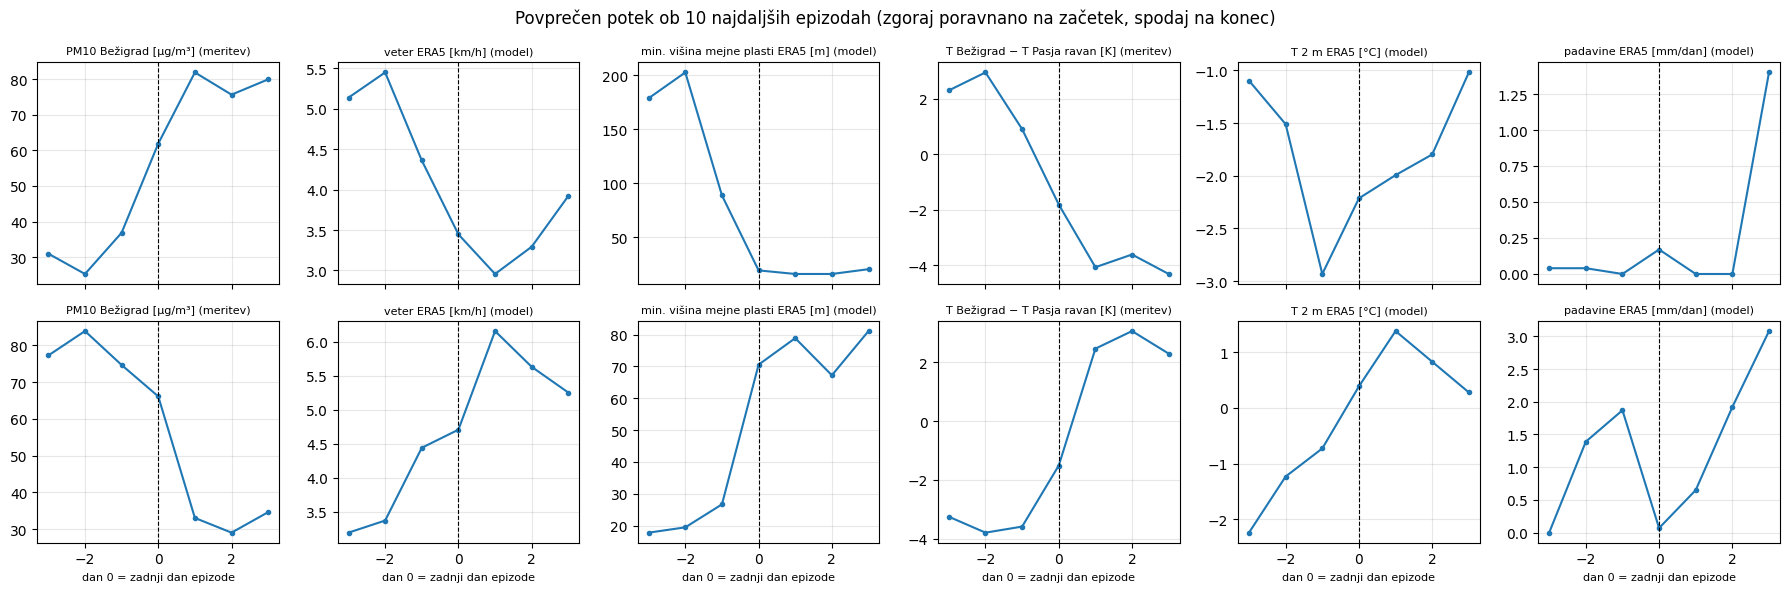

In [4]:
# dnevne vremenske spremenljivke
E = dnevno(era).set_index("dan")
E["blh_min"] = era.set_index("time_utc").boundary_layer_height.resample("D").min()
E["precip_sum"] = era.set_index("time_utc").precipitation.resample("D").sum(min_count=18)
I = dnevno(inv[["time_utc", "dt_bezigrad_pasja_ravan", "inv_pasja_ravan", "wind_speed_lj_bezigrad"]]).set_index("dan")
V = E.join(I).join(D[["pm10", "pm25"]])

spremenljivke = {"pm10": "PM10 Bežigrad [µg/m³] (meritev)", "wind_speed_10m": "veter ERA5 [km/h] (model)",
                 "blh_min": "min. višina mejne plasti ERA5 [m] (model)", "dt_bezigrad_pasja_ravan": "T Bežigrad − T Pasja ravan [K] (meritev)",
                 "temperature_2m": "T 2 m ERA5 [°C] (model)", "precip_sum": "padavine ERA5 [mm/dan] (model)"}
top = ep.sort_values("trajanje_dni", ascending=False).head(10)

def kompozit(ref_col):
    okna = []
    for _, r in top.iterrows():
        d0 = r[ref_col]
        w = V.loc[d0 - pd.Timedelta(days=3): d0 + pd.Timedelta(days=3), list(spremenljivke)].copy()
        w.index = ((w.index - d0).days)
        okna.append(w)
    return pd.concat(okna).groupby(level=0).mean()

fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True)
for row, (ref, naslov) in enumerate([("zacetek", "dan 0 = začetek epizode"), ("konec", "dan 0 = zadnji dan epizode")]):
    k = kompozit(ref)
    for ax, (col, lab) in zip(axes[row], spremenljivke.items()):
        ax.plot(k.index, k[col], marker="o", ms=3); ax.axvline(0, color="k", lw=.8, ls="--"); ax.grid(alpha=.3)
        ax.set_title(lab, fontsize=8)
        if row == 1: ax.set_xlabel(naslov, fontsize=8)
plt.suptitle("Povprečen potek ob 10 najdaljših epizodah (zgoraj poravnano na začetek, spodaj na konec)"); plt.tight_layout(); plt.show()

In [5]:
# kaj konča epizodo: primerjava zadnjega dne epizode in prvega dne po njej
po = []
for _, r in ep.iterrows():
    d1, d2 = r.konec, r.konec + pd.Timedelta(days=1)
    if d2 in V.index:
        po.append({"veter_med": V.loc[d1, "wind_speed_10m"], "veter_po": V.loc[d2, "wind_speed_10m"],
                   "padavine_po": V.loc[d2, "precip_sum"], "blh_med": V.loc[d1, "blh_min"], "blh_po": V.loc[d2, "blh_min"]})
po = pd.DataFrame(po)
print(f"Dan po koncu epizode (n = {len(po)}): veter ERA5 se v povprečju dvigne z {po.veter_med.mean():.1f} na {po.veter_po.mean():.1f} km/h,")
print(f"padavine > 1 mm ima {100*(po.padavine_po > 1).mean():.0f} % dni, min. višina mejne plasti se dvigne z {po.blh_med.mean():.0f} na {po.blh_po.mean():.0f} m.")
print(f"Delež koncev, kjer je dan po epizodi veter > 8 km/h ALI padavine > 1 mm: {100*((po.veter_po > 8) | (po.padavine_po > 1)).mean():.0f} %")

Dan po koncu epizode (n = 80): veter ERA5 se v povprečju dvigne z 4.6 na 6.0 km/h,
padavine > 1 mm ima 26 % dni, min. višina mejne plasti se dvigne z 35 na 65 m.
Delež koncev, kjer je dan po epizodi veter > 8 km/h ALI padavine > 1 mm: 40 %


## 3. Preprosto pravilo za opozorilo "jutri"

Pravilo iz treh vremenskih pogojev za jutrišnji dan (pozimi, nov–mar): **povprečni veter < 6 km/h** (1,7 m/s) **in povprečna višina mejne plasti < 300 m in padavine < 1 mm**. Primerjamo ga z dejanskim preseganjem PM10 na Bežigradu jutri. Drugo pravilo: **CAMS napoved dnevnega PM10 > 35 µg/m³**. Tretje: kombinacija (opozorilo, če velja katero koli).

Ker za nazaj nimamo shranjenih vremenskih napovedi, pogoje za "jutri" vzamemo iz ERA5 (analiza); uspešnost je zato **optimistična**. Pri resnični napovedi bo zadetkov manj, lažnih alarmov več.

**Četrto pravilo, CAMx ARSO (model):** dnevno povprečje napovedi CAMx PM10 **> 50 µg/m³** iz ur **+25 … +48** (zagon ob 00 UTC dan prej; napoved za jutri je znana zjutraj, torej pravočasno za obveščanje popoldne). To je pravo pravilo "za jutri" in ga ocenimo skupaj z ostalimi (na dneh, ko CAMx obstaja: zime 2023–2025). Posebej (spodaj) ocenimo še CAMx iz ur +1 … +24, ki je jutranje opozorilo za *isti* dan, proti preseganju istega dne, s CAMS za isti dan za primerjavo. CAMx je v paketu od 1. 1. 2023 (PM10 brez 26. 11. – 31. 12. 2024).

In [6]:
Cd = dnevno(cams).set_index("dan")
Cx = dnevno(camx[["time_utc", "camx_pm10", "camx_pm25"]]).set_index("dan")   # dnevno povprečje ur +1 … +24 (isti dan)
Cxj = dnevno(camx_j[["time_utc", "camx_pm10", "camx_pm25"]]).set_index("dan").add_suffix("_jutri_napoved")  # ure +25 … +48, po dnevu, na katerega se nanašajo
T = V.join(Cd[["cams_pm10"]]).join(Cx[["camx_pm10"]]).join(Cxj[["camx_pm10_jutri_napoved"]])
T["jutri_preseganje"] = T.pm10.shift(-1) > MEJA_PM10_DAN_EU
T["jutri_veljaven"] = T.pm10.shift(-1).notna()
T["blh"] = T.boundary_layer_height          # dnevno povprečje
for c in ["wind_speed_10m", "blh", "precip_sum", "cams_pm10"]:
    T[c + "_jutri"] = T[c].shift(-1)
T["camx_pm10_jutri"] = T.camx_pm10_jutri_napoved.shift(-1)   # napoved za jutri, izdana danes zjutraj
T["zima"] = T.index.month.isin(ZIMSKI_MESECI)
T["sezona"] = sezona(T.index.to_series())
Z = T[T.zima & T.jutri_veljaven & T.blh_jutri.notna()].copy()   # ERA5 nima mejne plasti za 1.–6. 2024

Z["pravilo_vreme"] = (Z.wind_speed_10m_jutri < 6) & (Z.blh_jutri < 300) & (Z.precip_sum_jutri < 1)
Z["pravilo_cams"] = Z.cams_pm10_jutri > 35
Z["pravilo_oboje"] = Z.pravilo_vreme | Z.pravilo_cams
Z["pravilo_camx"] = Z.camx_pm10_jutri > MEJA_PM10_DAN_EU   # CAMx za jutri (samo dnevi s CAMx, 2023–2025)

def ocena(pred, res):
    tp = int((pred & res).sum()); fp = int((pred & ~res).sum()); fn = int((~pred & res).sum()); tn = int((~pred & ~res).sum())
    return dict(opozoril=tp + fp, preseganj=tp + fn, zadetki=tp, lazni_alarmi=fp, zgreseni=fn, tihi_dnevi_ok=tn,
                obcutljivost=round(tp / (tp + fn), 2) if tp + fn else np.nan, delez_laznih=round(fp / (tp + fp), 2) if tp + fp else np.nan,
                natancnost=round(tp / (tp + fp), 2) if tp + fp else np.nan)
rez = pd.DataFrame({p: ocena(Z[p], Z.jutri_preseganje) for p in ["pravilo_vreme", "pravilo_cams", "pravilo_oboje"]}).T
print(f"Zimski dnevi z oceno: {len(Z)}, od tega preseganj jutri: {int(Z.jutri_preseganje.sum())} ({100*Z.jutri_preseganje.mean():.0f} % dni)")
Zc = Z[Z.camx_pm10_jutri.notna()]       # podmnožica s CAMx za jutri (zime 2023/24 – 2025/26 do konca 2025)
rez_c = pd.DataFrame({p: ocena(Zc[p], Zc.jutri_preseganje) for p in ["pravilo_vreme", "pravilo_cams", "pravilo_oboje", "pravilo_camx"]}).T
print(f"Isti dnevi s CAMx za jutri: {len(Zc)}, preseganj jutri: {int(Zc.jutri_preseganje.sum())}; CAMx za jutri {Zc.camx_pm10_jutri.mean():.1f} µg/m³ proti meritvi {Zc.pm10.shift(-1).reindex(Zc.index).mean():.1f} (r = {Zc.camx_pm10_jutri.corr(Zc.pm10.shift(-1).reindex(Zc.index)):.2f})")
display(rez)
rez_c

Zimski dnevi z oceno: 1512, od tega preseganj jutri: 167 (11 % dni)
Isti dnevi s CAMx za jutri: 361, preseganj jutri: 29; CAMx za jutri 35.3 µg/m³ proti meritvi 25.1 (r = 0.61)


,opozoril,preseganj,zadetki,lazni_alarmi,zgreseni,tihi_dnevi_ok,obcutljivost,delez_laznih,natancnost
pravilo_vreme,510.0,167.0,124.0,386.0,43.0,959.0,0.74,0.76,0.24
pravilo_cams,530.0,167.0,157.0,373.0,10.0,972.0,0.94,0.70,0.30
pravilo_oboje,716.0,167.0,166.0,550.0,1.0,795.0,0.99,0.77,0.23


,opozoril,preseganj,zadetki,lazni_alarmi,zgreseni,tihi_dnevi_ok,obcutljivost,delez_laznih,natancnost
pravilo_vreme,157.0,29.0,26.0,131.0,3.0,201.0,0.90,0.83,0.17
pravilo_cams,142.0,29.0,29.0,113.0,0.0,219.0,1.00,0.80,0.20
pravilo_oboje,195.0,29.0,29.0,166.0,0.0,166.0,1.00,0.85,0.15
pravilo_camx,83.0,29.0,18.0,65.0,11.0,267.0,0.62,0.78,0.22


In [7]:
# četrto pravilo: CAMx ARSO (model) za ISTI dan, znano zjutraj; ovrednoteno proti preseganju istega dne, zime 2023–2026
Zd = T[T.zima & T.camx_pm10.notna() & T.pm10.notna()].copy()
Zd["preseganje"] = Zd.pm10 > MEJA_PM10_DAN_EU                  # preseganje istega dne (meritev)
Zd["pravilo_camx_danes"] = Zd.camx_pm10 > MEJA_PM10_DAN_EU
Zd["pravilo_cams_danes"] = Zd.cams_pm10 > 35          # CAMS za isti dan, za pošteno primerjavo
rez_danes = pd.DataFrame({p: ocena(Zd[p], Zd.preseganje) for p in ["pravilo_camx_danes", "pravilo_cams_danes"]}).T
print(f"Zimski dnevi s CAMx ({Zd.index.min():%Y-%m-%d} – {Zd.index.max():%Y-%m-%d}): {len(Zd)}, preseganj isti dan: {int(Zd.preseganje.sum())}")
print(f"CAMx PM10 dnevno, Bežigrad, isti dnevi: model {Zd.camx_pm10.mean():.1f} µg/m³ proti meritvi {Zd.pm10.mean():.1f} µg/m³ (pristranskost {Zd.camx_pm10.mean() - Zd.pm10.mean():+.1f}, r = {Zd.camx_pm10.corr(Zd.pm10):.2f})")
print("Opomba: to NI napoved za jutri; pove, kako dober je CAMx kot jutranje opozorilo za tekoči dan.")
rez_danes

Zimski dnevi s CAMx (2023-01-01 – 2026-11-12): 510, preseganj isti dan: 38
CAMx PM10 dnevno, Bežigrad, isti dnevi: model 32.1 µg/m³ proti meritvi 24.6 µg/m³ (pristranskost +7.5, r = 0.65)
Opomba: to NI napoved za jutri; pove, kako dober je CAMx kot jutranje opozorilo za tekoči dan.


,opozoril,preseganj,zadetki,lazni_alarmi,zgreseni,tihi_dnevi_ok,obcutljivost,delez_laznih,natancnost
pravilo_camx_danes,83.0,38.0,18.0,65.0,20.0,407.0,0.47,0.78,0.22
pravilo_cams_danes,220.0,38.0,37.0,183.0,1.0,289.0,0.97,0.83,0.17


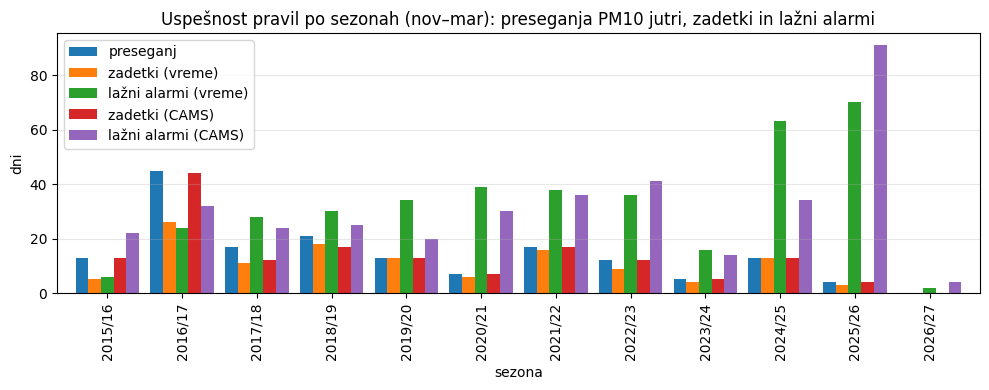

Matrika zamenjav, pravilo vreme (vrstice: opozorilo da/ne; stolpci: preseganje da/ne):
preseganje jutri  False  True 
opozorilo                     
False               959     43
True                386    124


In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
g = Z.groupby("sezona").apply(lambda d: pd.Series({"preseganj": d.jutri_preseganje.sum(),
     "zadetki (vreme)": (d.pravilo_vreme & d.jutri_preseganje).sum(), "lažni alarmi (vreme)": (d.pravilo_vreme & ~d.jutri_preseganje).sum(),
     "zadetki (CAMS)": (d.pravilo_cams & d.jutri_preseganje).sum(), "lažni alarmi (CAMS)": (d.pravilo_cams & ~d.jutri_preseganje).sum()}))
g.plot.bar(ax=ax, width=.85); ax.set(ylabel="dni", title="Uspešnost pravil po sezonah (nov–mar): preseganja PM10 jutri, zadetki in lažni alarmi")
ax.grid(alpha=.3, axis="y"); plt.tight_layout(); plt.show()
print("Matrika zamenjav, pravilo vreme (vrstice: opozorilo da/ne; stolpci: preseganje da/ne):")
print(pd.crosstab(Z.pravilo_vreme, Z.jutri_preseganje, rownames=["opozorilo"], colnames=["preseganje jutri"]))

In [9]:
# občutljivost pravila na pragove: kako se spreminjata občutljivost in delež lažnih alarmov
rows = []
for v in [4, 6, 8, 10]:
    for b in [200, 300, 500, 800]:
        p = (Z.wind_speed_10m_jutri < v) & (Z.blh_jutri < b) & (Z.precip_sum_jutri < 1)
        o = ocena(p, Z.jutri_preseganje); rows.append(dict(veter_km_h=v, blh_m=b, **o))
pr = pd.DataFrame(rows)
print("Pragovi (veter km/h, povprečna mejna plast m): občutljivost = delež ujetih preseganj; lažni = delež lažnih alarmov med opozorili")
pr.pivot(index="veter_km_h", columns="blh_m", values="obcutljivost").round(2).join(
    pr.pivot(index="veter_km_h", columns="blh_m", values="delez_laznih").round(2), lsuffix="_obcutlj", rsuffix="_lazni")

Pragovi (veter km/h, povprečna mejna plast m): občutljivost = delež ujetih preseganj; lažni = delež lažnih alarmov med opozorili


blh_m,200_obcutlj,300_obcutlj,500_obcutlj,800_obcutlj,200_lazni,300_lazni,500_lazni,800_lazni
veter_km_h,,,,,,,,
4,0.47,0.51,0.53,0.53,0.73,0.77,0.78,0.78
6,0.66,0.74,0.82,0.82,0.70,0.76,0.80,0.81
8,0.71,0.80,0.88,0.88,0.69,0.76,0.81,0.83
10,0.71,0.80,0.89,0.89,0.69,0.76,0.81,0.84


## 4. Kaj to pomeni za obveščanje

- Epizode se začnejo, ko veter pade in se mejna plast spusti, in se končajo z vetrom ali padavinami; temperaturna razlika Bežigrad–Pasja ravan je dober *izmerjen* znak, da je kotlina zaprta.
- Preseganje je redek dogodek (okoli desetina zimskih dni), zato ima vsako pravilo, ki ujame večino preseganj, veliko lažnih alarmov: vremensko pravilo ujame okoli tri četrtine preseganj, a so tri četrtine opozoril lažne; prag CAMS ujame več, a tudi z večino lažnih opozoril (CAMS zadnje zime precenjuje, glej `02_modeli/README.md`); kombinacija skoraj nič ne zgreši, opozarja pa več kot polovico zimskih dni.
- **CAMx ARSO** (4,4 km) kot **pravilo za jutri** (ure +25 … +48, prag 50 µg/m³ PM10) na 361 zimskih dneh 2023–2025 ujame 18 od 29 preseganj (občutljivost 0,62) s 65 lažnimi alarmi (78 % opozoril); napoved za jutri je v povprečju 35 µg/m³ proti izmerjenim 25 (r = 0,61). Kot jutranje opozorilo za isti dan (ure +1 … +24) ni nič boljši: 18 od 38 preseganj v zimah 2023–2026, tri četrtine opozoril lažnih; napovedi za jutri in za isti dan sta skoraj enaki (r = 0,94 po urah). Model na Bežigradu **precenjuje** in pristranskost raste (dnevno PM10 +1 µg/m³ v zimi 2022/23, +6 v 2023/24, +13 v 2024/25, +22 v nov–dec 2025), ima jutranji vrh ob 6–8 UTC, ki ga meritve nimajo, in zgreši ravno najvišje dni (dnevna korelacija 0,6–0,75). Pred uporabo ga je treba **umeriti** na meritve (odšteti drsečo pristranskost in prag nastaviti glede na ciljno občutljivost, kot pri CAMS). Glej `02_modeli/camx/README.md`. Odločevalec mora izbrati, kaj je dražje: zgrešeno preseganje ali lažni alarm. Za resnično rabo je treba uspešnost izmeriti na *napovedih* (zbirajte jih od zdaj naprej, Open-Meteo in ARSO), ne na analizi.
- Opozorilo ima smisel, če je vezano na konkretno ravnanje: kdo ga dobi (ranljive skupine, šole, občina), kaj naj naredi (ne kurite, ne prezračujte zvečer, omejitev prometa) in kdaj se prekliče.

## Kaj lahko ekipa iz tega naredi

1. **Sistem opozarjanja** z verjetnostjo preseganja za jutri iz napovedi Open-Meteo (vremenski pogoji) in CAMS, z nastavljivim pragom občutljivosti glede na ciljno skupino.
2. **Katalog epizod** kot interaktivna časovnica: za vsako epizodo vreme, inverzija, kaj jo je končalo; razlaga za javnost.
3. **Učenje pravila iz podatkov** (zvezek 03 pokaže model) namesto ročnih pragov, z oceno na zadnji zimi.
4. **Mestni protokol:** samodejno sporočilo občini dan prej s predlogom ukrepov in oceno, koliko dni na zimo bi bilo sproženih.
5. **Umerjen CAMx:** iz `02_modeli/camx/` oceniti pristranskost po urah in mesecih ter jo odšteti; ko ARSO pošlje ure +25 … +48, ponoviti razdelek 3 s CAMx kot pravim pravilom "za jutri" (`nalozi_camx(samo_isti_dan=False)`, `lead_h` 25–48).